In [1]:
# Import library yang dibutuhkan untuk Bagian 1
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


In [2]:
# Load dataset voice.csv
voice_path = 'voice.csv' if os.path.exists('voice.csv') else ('Jobsheet11/voice.csv' if os.path.exists('Jobsheet11/voice.csv') else '../Jobsheet9/voice.csv')
df_voice = pd.read_csv(voice_path)

print(f"Bentuk data (shape): {df_voice.shape}")
print("\nDistribusi label target:")
print(df_voice['label'].value_counts())
df_voice.head()


Bentuk data (shape): (3168, 21)

Distribusi label target:
label
male      1584
female    1584
Name: count, dtype: int64


,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male


In [3]:
# Pisahkan fitur independen (X) dan label target (y)
X_voice = df_voice.drop('label', axis=1)
y_voice = df_voice['label']

# Encode label: female -> 0, male -> 1
le = LabelEncoder()
y_voice_encoded = le.fit_transform(y_voice)

print(f"Fitur shape : {X_voice.shape}")
print(f"Target shape: {y_voice_encoded.shape}")
print("Mapping Label:", dict(zip(le.classes_, le.transform(le.classes_))))


Fitur shape : (3168, 20)
Target shape: (3168,)
Mapping Label: {'female': np.int64(0), 'male': np.int64(1)}


In [4]:
# Eksperimen dengan rasio 70:30 dan 80:20 untuk 3 kernel SVM
splits = {
    '70:30': {'test_size': 0.30, 'random_state': 42},
    '80:20': {'test_size': 0.20, 'random_state': 42}
}

kernels = {
    'Linear': SVC(kernel='linear', random_state=42),
    'Polynomial (degree=3)': SVC(kernel='poly', degree=3, random_state=42),
    'RBF': SVC(kernel='rbf', random_state=42)
}

results = []
trained_models = {}

for split_name, split_params in splits.items():
    # Split data
    X_train, X_test, y_train, y_test = train_test_split(
        X_voice, y_voice_encoded,
        test_size=split_params['test_size'],
        random_state=split_params['random_state'],
        stratify=y_voice_encoded
    )
    
    # Standarisasi fitur (penting untuk SVM)
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    for kernel_name, model in kernels.items():
        # Clone / re-instantiate model
        clf = SVC(kernel=model.kernel, degree=model.degree, random_state=42)
        clf.fit(X_train_scaled, y_train)
        
        # Prediksi
        y_train_pred = clf.predict(X_train_scaled)
        y_test_pred = clf.predict(X_test_scaled)
        
        # Hitung akurasi
        train_acc = accuracy_score(y_train, y_train_pred)
        test_acc = accuracy_score(y_test, y_test_pred)
        
        results.append({
            'Rasio Split': split_name,
            'Kernel': kernel_name,
            'Train Accuracy (%)': train_acc * 100,
            'Test Accuracy (%)': test_acc * 100
        })
        
        trained_models[(split_name, kernel_name)] = (clf, X_test_scaled, y_test, y_test_pred)

# Tampilkan tabel hasil
df_results = pd.DataFrame(results)
print("=== TABEL PERFORMANSI SVM PADA VOICE.CSV ===")
display(df_results)


=== TABEL PERFORMANSI SVM PADA VOICE.CSV ===


,Rasio Split,Kernel,Train Accuracy (%),Test Accuracy (%)
0,70:30,Linear,97.203428,97.896951
1,70:30,Polynomial (degree=3),96.662156,96.004206
2,70:30,RBF,98.376184,98.317560
3,80:20,Linear,97.671665,97.476341
4,80:20,Polynomial (degree=3),96.803473,95.583596
5,80:20,RBF,98.382005,98.264984


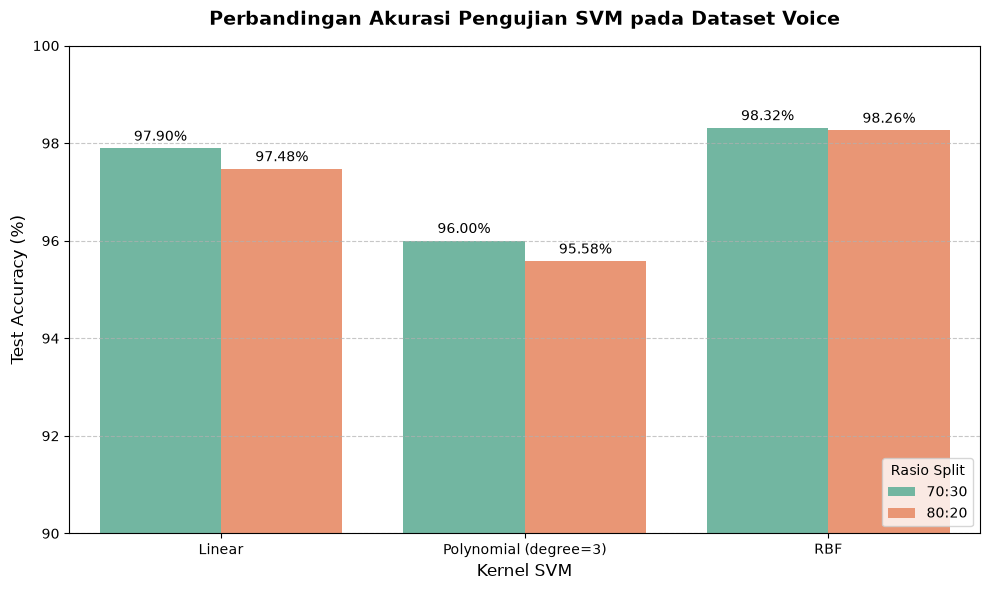

In [5]:
# Visualisasi Perbandingan Akurasi Antar Kernel dan Rasio Split
plt.figure(figsize=(10, 6))
palette = sns.color_palette("Set2", 2)
ax = sns.barplot(data=df_results, x='Kernel', y='Test Accuracy (%)', hue='Rasio Split', palette=palette)

plt.title('Perbandingan Akurasi Pengujian SVM pada Dataset Voice', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Kernel SVM', fontsize=12)
plt.ylabel('Test Accuracy (%)', fontsize=12)
plt.ylim(90, 100)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Anotasi nilai di atas bar
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f"{height:.2f}%",
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=10, xytext=(0, 3),
                    textcoords='offset points')

plt.legend(title='Rasio Split', loc='lower right')
plt.tight_layout()
plt.show()


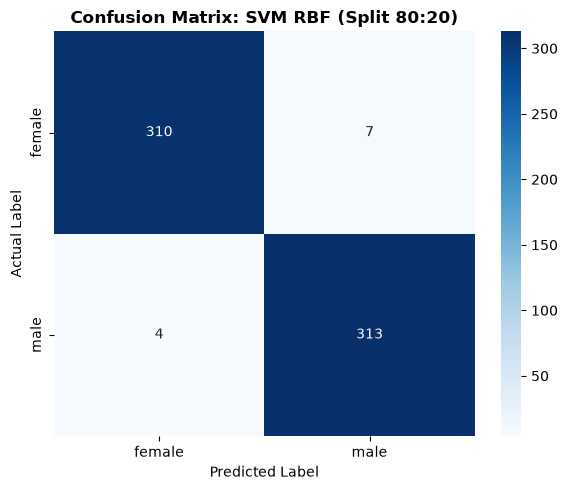

Classification Report SVM RBF (80:20):

              precision    recall  f1-score   support

      female       0.99      0.98      0.98       317
        male       0.98      0.99      0.98       317

    accuracy                           0.98       634
   macro avg       0.98      0.98      0.98       634
weighted avg       0.98      0.98      0.98       634



In [6]:
# Tampilkan Confusion Matrix & Classification Report untuk Model Terbaik (RBF Split 80:20)
best_model, X_test_scaled, y_test, y_pred = trained_models[('80:20', 'RBF')]

cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_, ax=ax)
plt.title('Confusion Matrix: SVM RBF (Split 80:20)', fontsize=12, fontweight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.tight_layout()
plt.show()

print("Classification Report SVM RBF (80:20):\n")
print(classification_report(y_test, y_pred, target_names=le.classes_))


In [7]:
# Import modul pengolahan citra dan tuning
from pathlib import Path
import cv2
import matplotlib.image as mpimg
from sklearn.model_selection import GridSearchCV


In [8]:
# Definisikan direktori citra
train_dir = 'images/training/' if os.path.exists('images/training/') else ('Jobsheet11/images/training/' if os.path.exists('Jobsheet11/images/training/') else 'images/images/training/')
test_dir = 'images/test/' if os.path.exists('images/test/') else ('Jobsheet11/images/test/' if os.path.exists('Jobsheet11/images/test/') else 'images/images/test/')

def load_all_images(base_dirs):
    all_images = []
    for b_dir in base_dirs:
        p = Path(b_dir)
        dirs = [d for d in p.glob('*') if d.is_dir() and not d.name.startswith('.')]
        for d in dirs:
            label = d.name
            for file in d.glob('*.jpg'):
                img = mpimg.imread(str(file))
                if img is not None:
                    # Resize standar agar konsisten
                    std_img = cv2.resize(img, (1100, 600))
                    # Encode label: day=1, night=0
                    encoded_label = 1 if label == 'day' else 0
                    all_images.append((std_img, encoded_label, label))
    return all_images

dataset_images = load_all_images([train_dir, test_dir])
print(f"Total seluruh citra yang dimuat: {len(dataset_images)}")
day_count = sum(1 for item in dataset_images if item[1] == 1)
night_count = sum(1 for item in dataset_images if item[1] == 0)
print(f"Jumlah citra Siang (Day)  : {day_count}")
print(f"Jumlah citra Malam (Night): {night_count}")


Total seluruh citra yang dimuat: 400
Jumlah citra Siang (Day)  : 200
Jumlah citra Malam (Night): 200


In [9]:
def extract_histogram_features(image, bins=(32, 32, 32)):
    # Ubah colorspace citra ke HSV
    hsv_img = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)
    
    # Hitung histogram untuk setiap saluran: H, S, V
    hist_h = cv2.calcHist([hsv_img], [0], None, [bins[0]], [0, 180])
    hist_s = cv2.calcHist([hsv_img], [1], None, [bins[1]], [0, 256])
    hist_v = cv2.calcHist([hsv_img], [2], None, [bins[2]], [0, 256])
    
    # Normalisasi histogram agar tidak bergantung pada jumlah piksel absolut
    cv2.normalize(hist_h, hist_h)
    cv2.normalize(hist_s, hist_s)
    cv2.normalize(hist_v, hist_v)
    
    # Gabungkan menjadi satu vektor fitur 1D (32 + 32 + 32 = 96 fitur)
    feature_vector = np.concatenate([hist_h, hist_s, hist_v]).flatten()
    return feature_vector

# Ekstraksi fitur untuk seluruh dataset
X_hist = []
y_hist = []

for img, label_code, _ in dataset_images:
    feat = extract_histogram_features(img)
    X_hist.append(feat)
    y_hist.append(label_code)

X_hist = np.array(X_hist)
y_hist = np.array(y_hist)

print(f"Dimensi matriks fitur X_hist: {X_hist.shape}")
print(f"Dimensi vektor label y_hist  : {y_hist.shape}")


Dimensi matriks fitur X_hist: (400, 96)
Dimensi vektor label y_hist  : (400,)


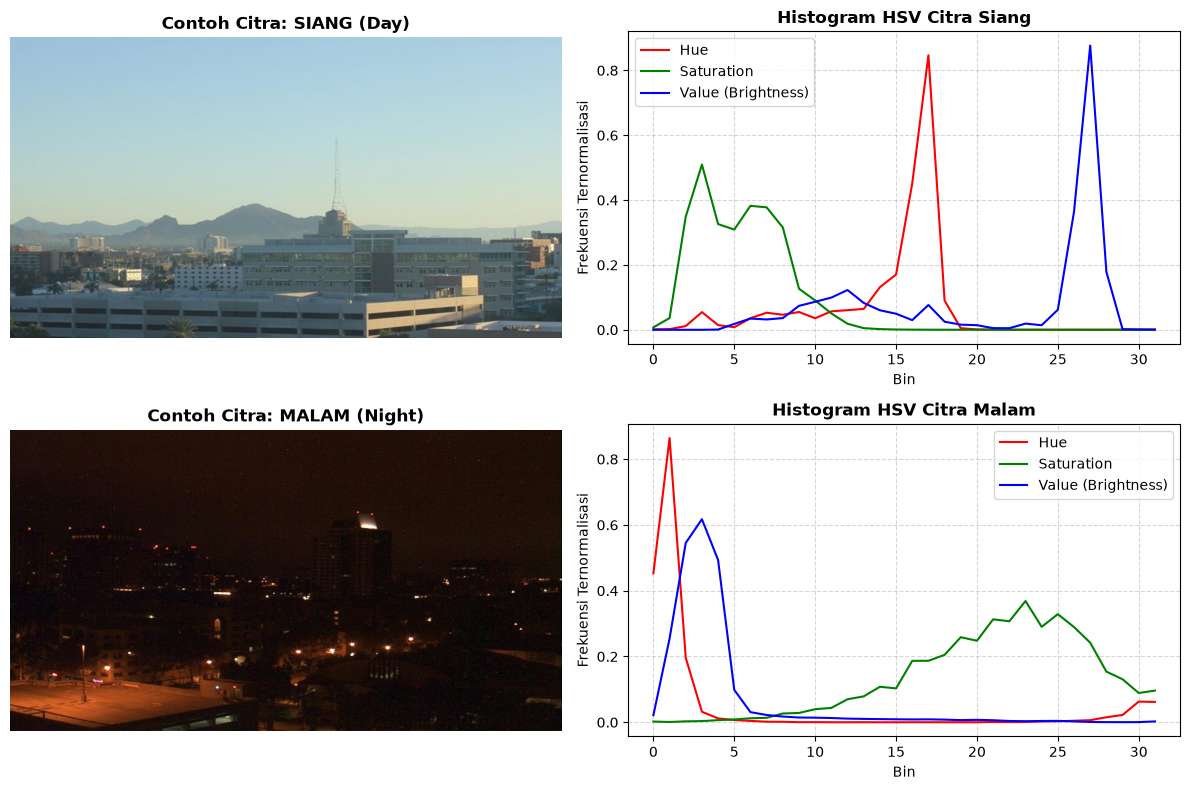

In [10]:
# Visualisasi perbandingan histogram citra Siang vs citra Malam
sample_day = next(item[0] for item in dataset_images if item[1] == 1)
sample_night = next(item[0] for item in dataset_images if item[1] == 0)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Tampilkan citra
axes[0, 0].imshow(sample_day)
axes[0, 0].set_title('Contoh Citra: SIANG (Day)', fontweight='bold')
axes[0, 0].axis('off')

axes[1, 0].imshow(sample_night)
axes[1, 0].set_title('Contoh Citra: MALAM (Night)', fontweight='bold')
axes[1, 0].axis('off')

# Plot histogram HSV
day_hsv = cv2.cvtColor(sample_day, cv2.COLOR_RGB2HSV)
night_hsv = cv2.cvtColor(sample_night, cv2.COLOR_RGB2HSV)

colors = ('r', 'g', 'b')
labels = ('Hue', 'Saturation', 'Value (Brightness)')

for i, (col, lbl) in enumerate(zip(colors, labels)):
    max_range = 180 if i == 0 else 256
    hist_day = cv2.calcHist([day_hsv], [i], None, [32], [0, max_range])
    hist_night = cv2.calcHist([night_hsv], [i], None, [32], [0, max_range])
    cv2.normalize(hist_day, hist_day)
    cv2.normalize(hist_night, hist_night)
    
    axes[0, 1].plot(hist_day, color=col, label=lbl)
    axes[1, 1].plot(hist_night, color=col, label=lbl)

axes[0, 1].set_title('Histogram HSV Citra Siang', fontweight='bold')
axes[0, 1].set_xlabel('Bin')
axes[0, 1].set_ylabel('Frekuensi Ternormalisasi')
axes[0, 1].legend()
axes[0, 1].grid(True, linestyle='--', alpha=0.5)

axes[1, 1].set_title('Histogram HSV Citra Malam', fontweight='bold')
axes[1, 1].set_xlabel('Bin')
axes[1, 1].set_ylabel('Frekuensi Ternormalisasi')
axes[1, 1].legend()
axes[1, 1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


In [11]:
# Split data dengan rasio 80:20 sesuai instruksi soal
X_train_img, X_test_img, y_train_img, y_test_img = train_test_split(
    X_hist, y_hist,
    test_size=0.20,
    random_state=42,
    stratify=y_hist
)

# Standarisasi fitur histogram
scaler_img = StandardScaler()
X_train_img_scaled = scaler_img.fit_transform(X_train_img)
X_test_img_scaled = scaler_img.transform(X_test_img)

print(f"Data latih  : {X_train_img_scaled.shape[0]} sampel")
print(f"Data uji    : {X_test_img_scaled.shape[0]} sampel")


Data latih  : 320 sampel
Data uji    : 80 sampel


In [12]:
# 1. Baseline Model SVM RBF (Default)
baseline_svm = SVC(kernel='rbf', random_state=42)
baseline_svm.fit(X_train_img_scaled, y_train_img)

base_train_pred = baseline_svm.predict(X_train_img_scaled)
base_test_pred = baseline_svm.predict(X_test_img_scaled)

base_train_acc = accuracy_score(y_train_img, base_train_pred)
base_test_acc = accuracy_score(y_test_img, base_test_pred)

print(f"Baseline SVM RBF - Train Acc: {base_train_acc * 100:.2f}%")
print(f"Baseline SVM RBF - Test Acc : {base_test_acc * 100:.2f}%")

# 2. Hyperparameter Tuning menggunakan GridSearchCV
param_grid = {
    'C': [0.1, 1, 5, 10, 50, 100],
    'gamma': ['scale', 'auto', 0.001, 0.01, 0.1]
}

print("\nMenjalankan GridSearchCV untuk tuning parameter C dan gamma...")
grid_search = GridSearchCV(
    estimator=SVC(kernel='rbf', random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)
grid_search.fit(X_train_img_scaled, y_train_img)

best_svm = grid_search.best_estimator_
print(f"Parameter Terbaik (Best Params): {grid_search.best_params_}")
print(f"Best CV Score                  : {grid_search.best_score_ * 100:.2f}%")

# Evaluasi model terbaik pada data uji
tuned_train_pred = best_svm.predict(X_train_img_scaled)
tuned_test_pred = best_svm.predict(X_test_img_scaled)

tuned_train_acc = accuracy_score(y_train_img, tuned_train_pred)
tuned_test_acc = accuracy_score(y_test_img, tuned_test_pred)

print(f"\nTuned SVM RBF - Train Acc: {tuned_train_acc * 100:.2f}%")
print(f"Tuned SVM RBF - Test Acc : {tuned_test_acc * 100:.2f}%")


Baseline SVM RBF - Train Acc: 100.00%
Baseline SVM RBF - Test Acc : 97.50%

Menjalankan GridSearchCV untuk tuning parameter C dan gamma...


Parameter Terbaik (Best Params): {'C': 1, 'gamma': 'scale'}
Best CV Score                  : 100.00%

Tuned SVM RBF - Train Acc: 100.00%
Tuned SVM RBF - Test Acc : 97.50%


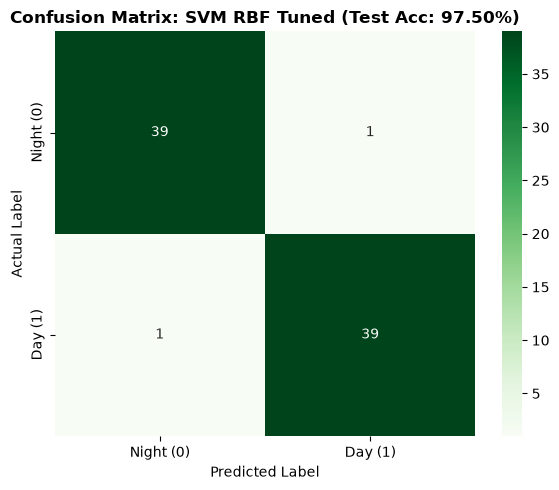

Classification Report:

              precision    recall  f1-score   support

       Night       0.97      0.97      0.97        40
         Day       0.97      0.97      0.97        40

    accuracy                           0.97        80
   macro avg       0.97      0.97      0.97        80
weighted avg       0.97      0.97      0.97        80



In [13]:
# Confusion Matrix & Classification Report Tuned Model
cm_img = confusion_matrix(y_test_img, tuned_test_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_img, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Night (0)', 'Day (1)'],
            yticklabels=['Night (0)', 'Day (1)'])
plt.title(f"Confusion Matrix: SVM RBF Tuned (Test Acc: {tuned_test_acc*100:.2f}%)", fontweight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.tight_layout()
plt.show()

print("Classification Report:\n")
print(classification_report(y_test_img, tuned_test_pred, target_names=['Night', 'Day']))


In [14]:
# Tabel Perbandingan Praktikum 5 vs Tugas Praktikum
df_compare = pd.DataFrame([
    {
        'Metode / Fitur': 'Threshold Kecerahan Rata-rata (Praktikum 5)',
        'Train Accuracy (%)': 84.17,
        'Test Accuracy (%)': 86.88,
        'Keterangan': '1 fitur skalar (ambang batas manual = 120)'
    },
    {
        'Metode / Fitur': 'SVM RBF + Kecerahan Rata-rata (Praktikum 5)',
        'Train Accuracy (%)': 85.83,
        'Test Accuracy (%)': 90.00,
        'Keterangan': '1 fitur skalar (Value rata-rata)'
    },
    {
        'Metode / Fitur': 'SVM RBF Baseline + Fitur Histogram HSV (Tugas)',
        'Train Accuracy (%)': base_train_acc * 100,
        'Test Accuracy (%)': base_test_acc * 100,
        'Keterangan': '96 fitur vektor histogram (C=1.0, gamma=scale)'
    },
    {
        'Metode / Fitur': 'SVM RBF Tuned + Fitur Histogram HSV (Tugas)',
        'Train Accuracy (%)': tuned_train_acc * 100,
        'Test Accuracy (%)': tuned_test_acc * 100,
        'Keterangan': f'Tuned: C={grid_search.best_params_["C"]}, gamma={grid_search.best_params_["gamma"]}'
    }
])

print("=== TABEL PERBANDINGAN PERFORMA FITUR CITRA SIANG & MALAM ===")
display(df_compare)


=== TABEL PERBANDINGAN PERFORMA FITUR CITRA SIANG & MALAM ===


,Metode / Fitur,Train Accuracy (%),Test Accuracy (%),Keterangan
0,Threshold Kecerahan Rata-rata (Praktikum 5),84.17,86.88,1 fitur skalar (ambang batas manual = 120)
1,SVM RBF + Kecerahan Rata-rata (Praktikum 5),85.83,90.00,1 fitur skalar (Value rata-rata)
2,SVM RBF Baseline + Fitur Histogram HSV (Tugas),100.00,97.50,"96 fitur vektor histogram (C=1.0, gamma=scale)"
3,SVM RBF Tuned + Fitur Histogram HSV (Tugas),100.00,97.50,"Tuned: C=1, gamma=scale"
